# Module 3: Statistics toolkit — random walks, stationarity, regression

Statistical arbitrage rests on one question: **is this spread stationary?** Before we can
test that (Module 5), we need the vocabulary (random walk, AR(1), stationarity, unit root,
autocorrelation), the workhorse estimator (ordinary least squares, OLS) with its error bars,
and the main trap: **spurious regression**.

Everything is simulated first, where the truth is known; real data appears only in
Section 5.

1. Three basic processes and their autocorrelation functions
2. Ensembles: diffusion vs a particle in a trap
3. OLS by hand, hypothesis tests, and robust (HAC) error bars
4. Spurious regression
5. Real data: SPY returns and volatility clustering
6. Exercises

Lecture notes, glossary and interview questions: [`lecture.md`](lecture.md).
New code: `statarb.simulate`, `statarb.stats`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats as sps
from statsmodels.tsa.stattools import pacf

from statarb import data, returns, simulate, stats

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(2026)

# Figures used in lecture.md are saved here; each uses its own seed so it is reproducible.
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


def plot_acf(ax, rho: pd.Series, nobs: int, title: str) -> None:
    ax.bar(rho.index[1:], rho.iloc[1:], width=0.6)
    band = stats.acf_band(nobs)
    ax.axhspan(-band, band, color="C1", alpha=0.2, label="±1.96/√T")
    ax.set_ylim(-0.3, 1.05)
    ax.set_xlabel("lag k")
    ax.set_title(title)

## 1. Three basic processes

With i.i.d. shocks $\varepsilon_t \sim \mathcal N(0, \sigma^2)$:

- **White noise:** $x_t = \varepsilon_t$. No memory at all.
- **AR(1)** (autoregressive of order 1): $x_t = c + \phi x_{t-1} + \varepsilon_t$. Each
  value remembers a fraction $\phi$ of the previous one. Stationary when $\lvert\phi\rvert \lt 1$.
- **Random walk:** $x_t = x_{t-1} + \varepsilon_t$, the AR(1) with $\phi = 1$ (a **unit
  root**). Shocks never decay.

The **autocorrelation function** (ACF) $\rho_k = \operatorname{Corr}(x_t, x_{t-k})$ is
the fingerprint of each. For AR(1), $\rho_k = \phi^k$. The shaded band, $\pm 1.96/\sqrt T$,
is where 95% of sample autocorrelations of *white noise* fall.

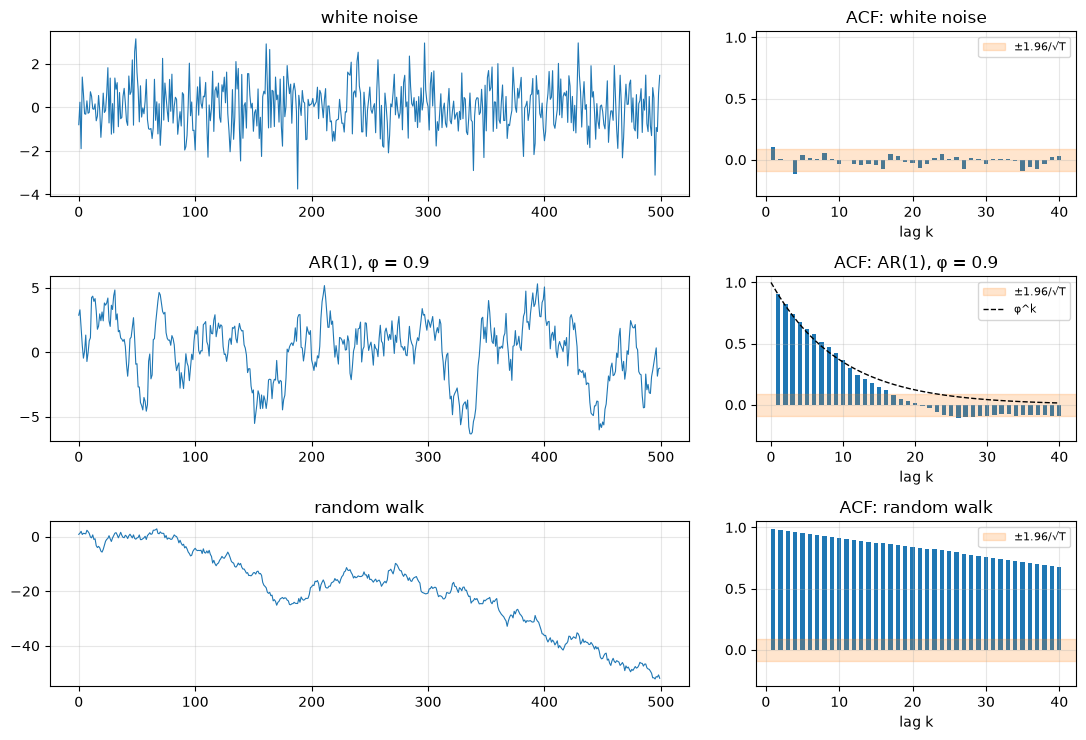

In [2]:
n = 500
series = {
    "white noise": simulate.white_noise(n, seed=rng),
    "AR(1), φ = 0.9": simulate.ar1(n, 0.9, seed=rng),
    "random walk": simulate.random_walk(n, seed=rng),
}

fig, axes = plt.subplots(3, 2, figsize=(11, 7.5), gridspec_kw={"width_ratios": [2, 1]})
for (name, x), (ax_ts, ax_acf) in zip(series.items(), axes, strict=True):
    ax_ts.plot(x, lw=0.8)
    ax_ts.set_title(name)
    plot_acf(ax_acf, stats.acf(x, 40), n, f"ACF: {name}")
    if name.startswith("AR"):
        ax_acf.plot(np.arange(41), 0.9 ** np.arange(41), "k--", lw=1, label="φ^k")
    ax_acf.legend(fontsize=8)
fig.tight_layout()

- White noise: every autocorrelation is inside the band (about 1 in 20 pokes out by
  chance, which is what a 95% band means).
- AR(1): geometric decay, $0.9^k$, with a **correlation time**
  $\tau = -1/\ln\phi \approx 9.5$ steps. The sample ACF is noisy around the theoretical
  curve.
- Random walk: the sample ACF starts near 1 and decays only slowly and roughly linearly.
  That slow decay is the visual signature of a unit root. (The theoretical ACF of a
  random walk isn't even defined, because its variance isn't constant.)

The **partial autocorrelation function** (PACF) at lag $k$ is the correlation between
$x_t$ and $x_{t-k}$ after removing the effect of the lags in between. For an AR(1), only
lag 1 matters directly, so its PACF cuts off after lag 1:

In [3]:
ar = series["AR(1), φ = 0.9"]
pd.DataFrame({"ACF": stats.acf(ar, 5), "PACF": pacf(ar, nlags=5)}).T

lag,0,1,2,3,4,5
ACF,1.0,0.9067,0.8212,0.7424,0.6782,0.6221
PACF,1.0,0.9085,-0.0051,-0.0082,0.0412,0.0147


## 2. Ensembles: diffusion vs a particle in a trap

### 2a. Variance across the ensemble

One path can mislead. Simulate an **ensemble** of 2,000 independent paths and look at the
variance across paths at each time, $\operatorname{Var}(x_t)$.

For the random walk, $x_t = \sum_{s \le t} \varepsilon_s$, so
$\operatorname{Var}(x_t) = t\sigma^2$, growing without bound: free diffusion, $\langle x^2\rangle = 2Dt$ with
$2D = \sigma^2$. For the AR(1), the pull back towards the mean balances the shocks, and the
variance saturates: a particle in a harmonic trap. (Here both start at 0, so the AR(1) needs
a few correlation times to relax to equilibrium.)

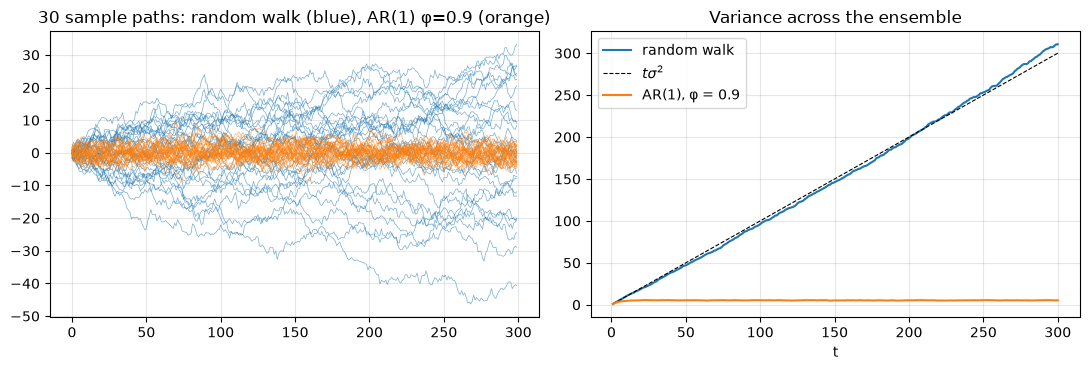

In [4]:
n_paths, n_steps = 2000, 300
rw_ens = simulate.random_walk(n_steps, n_paths=n_paths, seed=rng)
ar_ens = simulate.ar1(n_steps, 0.9, x0=0.0, n_paths=n_paths, seed=rng)
t = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(rw_ens[:, :30], lw=0.5, color="C0", alpha=0.6)
axes[0].plot(ar_ens[:, :30], lw=0.5, color="C1", alpha=0.6)
axes[0].set_title("30 sample paths: random walk (blue), AR(1) φ=0.9 (orange)")
axes[1].plot(t, rw_ens.var(axis=1), label="random walk")
axes[1].plot(t, t, "k--", lw=0.8, label=r"$t\sigma^2$")
axes[1].plot(t, ar_ens.var(axis=1), label="AR(1), φ = 0.9")
axes[1].set_xlabel("t")
axes[1].set_title("Variance across the ensemble")
axes[1].legend()
fig.tight_layout()

This is the distinction everything in stat arb hinges on:

- A **stationary** series (AR(1) with $\lvert\phi\rvert \lt 1$) has a constant mean and variance and
  keeps coming back. A spread like this can be traded: when it is far from its mean, it is
  likely to return.
- A **non-stationary** series (random walk) has no fixed level to return to. Its variance
  grows with time; "far from the mean" means nothing.

### 2b. Constant spread vs growing spread

The same idea as a picture. For each process, 2,000 paths: the ensemble mean (black), the
bands mean ± 1 and ± 2 ensemble standard deviations (shaded), and the theoretical ± 2σ band
(dashed). The y-axis is shared, so the spreads can be compared directly. White noise and
AR(1) start in equilibrium.

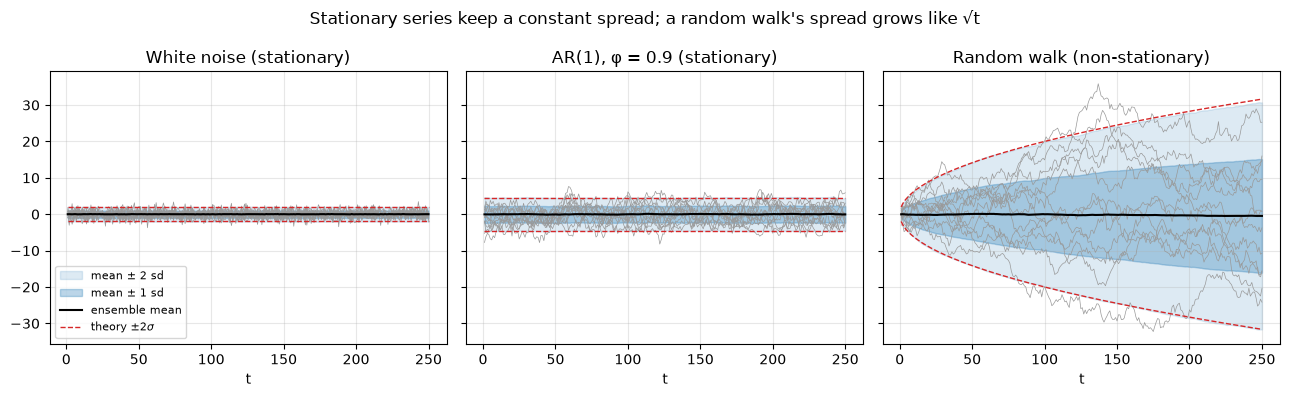

In [5]:
fig_rng = np.random.default_rng(31)
n_steps, n_paths, phi = 250, 2000, 0.9
t = np.arange(1, n_steps + 1)
ensembles = {
    "White noise (stationary)": (
        simulate.white_noise(n_steps, n_paths=n_paths, seed=fig_rng),
        np.full(n_steps, 1.0),
    ),
    "AR(1), φ = 0.9 (stationary)": (
        simulate.ar1(n_steps, phi, n_paths=n_paths, seed=fig_rng),
        np.full(n_steps, 1 / np.sqrt(1 - phi**2)),
    ),
    "Random walk (non-stationary)": (
        simulate.random_walk(n_steps, n_paths=n_paths, seed=fig_rng),
        np.sqrt(t),
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (title, (paths, sd_theory)) in zip(axes, ensembles.items(), strict=True):
    mean, sd = paths.mean(axis=1), paths.std(axis=1)
    ax.plot(t, paths[:, :12], color="0.6", lw=0.5)
    ax.fill_between(t, mean - 2 * sd, mean + 2 * sd, color="C0", alpha=0.15, label="mean ± 2 sd")
    ax.fill_between(t, mean - sd, mean + sd, color="C0", alpha=0.3, label="mean ± 1 sd")
    ax.plot(t, mean, "k", lw=1.5, label="ensemble mean")
    ax.plot(t, 2 * sd_theory, "C3--", lw=1, label=r"theory $\pm 2\sigma$")
    ax.plot(t, -2 * sd_theory, "C3--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("t")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Stationary series keep a constant spread; a random walk's spread grows like √t")
fig.tight_layout()
save(fig, "stationarity-ensembles.png")

### 2c. One path: rolling mean and standard deviation

In practice we see *one* path, not an ensemble. A rolling window (here 100 steps) gives a
local mean and standard deviation. For a stationary series both hover around fixed values.
For a random walk the rolling mean wanders off with the path, so no fixed "mean ± k
standard deviations" exists to trade against.

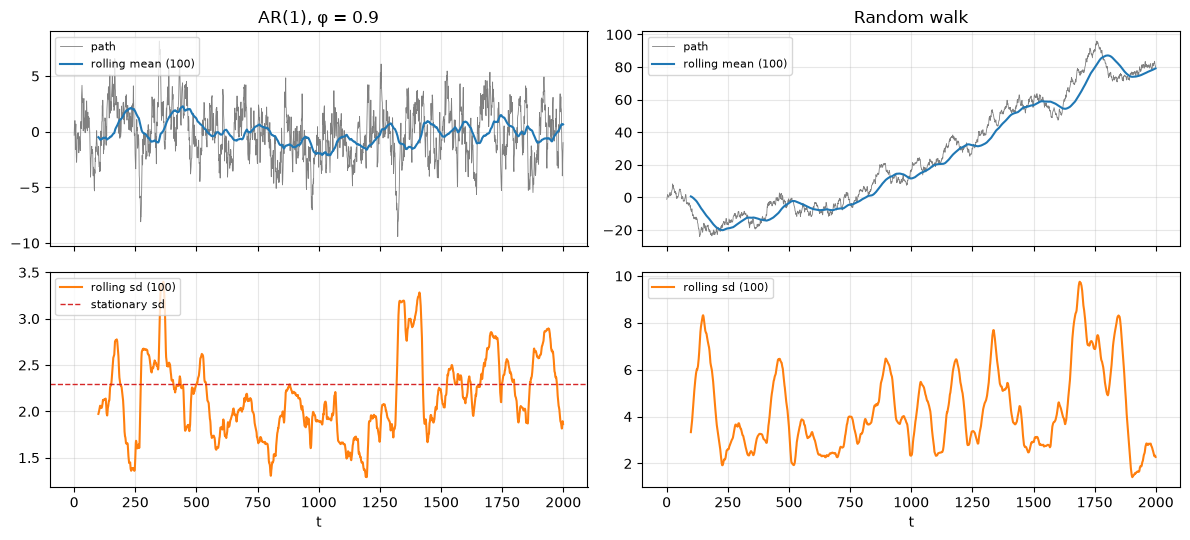

In [6]:
path_rng = np.random.default_rng(32)
n_long, window = 2000, 100
single = {
    "AR(1), φ = 0.9": simulate.ar1(n_long, phi, seed=path_rng),
    "Random walk": simulate.random_walk(n_long, seed=path_rng),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for col, (title, x) in enumerate(single.items()):
    s = pd.Series(x)
    axes[0, col].plot(s, lw=0.6, color="0.5", label="path")
    axes[0, col].plot(s.rolling(window).mean(), "C0", lw=1.5, label=f"rolling mean ({window})")
    axes[0, col].set_title(title)
    axes[0, col].legend(fontsize=8, loc="upper left")
    axes[1, col].plot(s.rolling(window).std(), "C1", lw=1.5, label=f"rolling sd ({window})")
    axes[1, col].set_xlabel("t")
    axes[1, col].legend(fontsize=8, loc="upper left")
axes[1, 0].axhline(1 / np.sqrt(1 - phi**2), color="C3", ls="--", lw=1, label="stationary sd")
axes[1, 0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save(fig, "rolling-moments.png")

For the AR(1) the rolling standard deviation fluctuates around, and on average a little
below, the stationary value: a 100-step window spans only about ten correlation times, so
it rarely sees the full range of the process. For the random walk the rolling standard
deviation swings between about 2 and 10: each window measures how far the path happened
to travel within it, not a fixed property of the process. (The *ensemble* spread is what
grows like $\sqrt t$, as in Section 2b.)

### 2d. Differencing an I(1) process

**Order of integration.** A series is $I(1)$ if it must be differenced once to become
stationary, $I(0)$ if it is stationary already. Differencing a random walk,
$\Delta x_t = x_t - x_{t-1} = \varepsilon_t$, gives back the white-noise shocks, so a
random walk is $I(1)$. The ACF shows the change: from a slow, near-linear decay to nothing
outside the white-noise band.

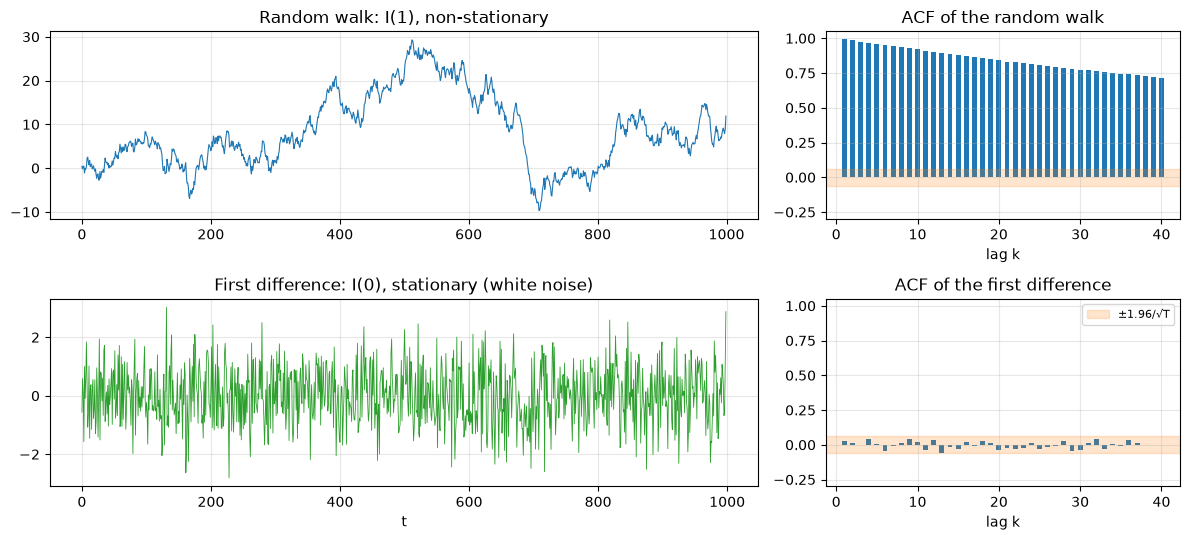

In [7]:
walk = simulate.random_walk(1000, seed=np.random.default_rng(33))
diffed = np.diff(walk)

fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0, 0].plot(walk, lw=0.8)
axes[0, 0].set_title("Random walk: I(1), non-stationary")
plot_acf(axes[0, 1], stats.acf(walk, 40), len(walk), "ACF of the random walk")
axes[1, 0].plot(diffed, lw=0.6, color="C2")
axes[1, 0].set_title("First difference: I(0), stationary (white noise)")
axes[1, 0].set_xlabel("t")
plot_acf(axes[1, 1], stats.acf(diffed, 40), len(diffed), "ACF of the first difference")
axes[1, 1].legend(fontsize=8)
fig.tight_layout()
save(fig, "differencing-random-walk.png")

Log prices are approximately $I(1)$, and returns (their first differences) approximately
$I(0)$; Section 5 shows this on SPY.

## 3. Ordinary least squares

### 3a. By hand vs `statsmodels`

Model: $y = X\beta + \varepsilon$, with $X$ an $n \times k$ matrix whose first column is
ones (the intercept). OLS minimises the sum of squared residuals, which gives

$$
\hat\beta = (X^\top X)^{-1}X^\top y, \qquad \hat\sigma^2 = \frac{e^\top e}{n-k}, \qquad
\widehat{\operatorname{Var}}(\hat\beta) = \hat\sigma^2 (X^\top X)^{-1},
$$

with residuals $e = y - X\hat\beta$. Simulate $y = 1 + 2x + \varepsilon$ and compute it
all with NumPy:

In [8]:
n = 100
x = rng.normal(size=n)
y = 1.0 + 2.0 * x + rng.normal(0, 1.5, n)

X = np.column_stack([np.ones(n), x])
k = X.shape[1]
beta_hat = np.linalg.solve(X.T @ X, X.T @ y)
resid = y - X @ beta_hat
sigma2_hat = resid @ resid / (n - k)
se = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X)))
t_stat = beta_hat / se
p_value = 2 * sps.t.sf(np.abs(t_stat), df=n - k)
r2 = 1 - resid @ resid / np.sum((y - y.mean()) ** 2)

by_hand = pd.DataFrame(
    {"coef": beta_hat, "std_err": se, "t": t_stat, "p_value": p_value}, index=["const", "x"]
)
print(f"R² = {r2:.4f}")
by_hand

R² = 0.7160


,coef,std_err,t,p_value
const,1.0112,0.1499,6.7443,1.0773e-09
x,2.1557,0.1371,15.7195,1.5367e-28


In [9]:
print(sm.OLS(y, sm.add_constant(x)).fit().summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.716
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     247.1
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.54e-28
Time:                        20:20:15   Log-Likelihood:                -181.15
No. Observations:                 100   AIC:                             366.3
Df Residuals:                      98   BIC:                             371.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0112      0.150      6.744      0.0

The numbers match. What each line of the summary means:

| Item | Meaning |
|---|---|
| `coef` | $\hat\beta$: the fitted intercept and slope (true values 1 and 2) |
| `std err` | Standard error: the estimated standard deviation of $\hat\beta$ across hypothetical repeated samples |
| `t` | $t = \hat\beta / \text{SE}$: how many standard errors the estimate is from 0 |
| `P>\|t\|` | p-value: probability of a $\lvert t\rvert$ at least this large *if the true coefficient were 0* |
| `[0.025 0.975]` | 95% confidence interval, $\hat\beta \pm t_{0.975, n-k} \text{SE}$ |
| `R-squared` | Fraction of the variance of $y$ explained by the fit |
| `Adj. R-squared` | $R^2$ penalised for the number of regressors |
| `F-statistic` | Test that all slopes are zero together |
| `Log-Likelihood`, `AIC`, `BIC` | Gaussian likelihood of the fit and information criteria for comparing models (Module 10) |
| `Durbin-Watson` | Checks residual autocorrelation: about 2 if none, near 0 if strongly positive |
| `Omnibus`, `Jarque-Bera`, `Skew`, `Kurtosis` | Tests whether the residuals look Gaussian |
| `Cond. No.` | Condition number of $X$: large values warn of nearly collinear regressors |

`statarb.stats.ols` wraps this and returns just what the project needs:

In [10]:
fit = stats.ols(y, x)
print(f"R² = {fit.rsquared:.4f}, residual variance = {fit.sigma2:.3f}")
fit.table()

R² = 0.7160, residual variance = 2.237


,coef,std_err,t,p_value
const,1.0112,0.1499,6.7443,1.0773e-09
x,2.1557,0.1371,15.7195,1.5367e-28


### 3b. What a hypothesis test promises

A test of $H_0: \beta = 0$ at **significance level** 5% rejects when $p \lt 0.05$. If the
assumptions hold, then, when $H_0$ is true, it rejects 5% of the time: that is the **type I
error** rate (false positive). When $H_0$ is false, the probability of rejecting is the
**power**; failing to reject is a **type II error** (false negative). Check both by
simulation:

In [11]:
def rejection_rate(beta: float, n: int, trials: int = 2000) -> float:
    rejections = 0
    for _ in range(trials):
        x = rng.normal(size=n)
        y = beta * x + rng.normal(size=n)
        rejections += stats.ols(y, x).pvalues["x"] < 0.05
    return rejections / trials


tests = pd.DataFrame(
    {
        "n = 50": [rejection_rate(0.0, 50), rejection_rate(0.2, 50)],
        "n = 500": [rejection_rate(0.0, 500), rejection_rate(0.2, 500)],
    },
    index=["true β = 0 (type I error rate)", "true β = 0.2 (power)"],
)
tests

,n = 50,n = 500
true β = 0 (type I error rate),0.0540,0.056
true β = 0.2 (power),0.2715,0.993


The false-positive rate is about 5% whatever the sample size, as promised. Power grows
with $n$: a small true effect is usually missed with 50 observations and almost always
found with 500.

### 3c. When the error bars lie: autocorrelation and HAC

The textbook standard error assumes errors that are uncorrelated and have constant
variance (**homoskedastic**). Financial time series violate both: errors are often
autocorrelated, and their variance changes over time (**heteroskedasticity**).

Repeat the type I error experiment with a persistent regressor and persistent errors, both
AR(1) with $\phi = 0.9$ and independent of each other, so the true slope is still 0:

In [12]:
trials, n = 1000, 300
naive, hac = 0, 0
for _ in range(trials):
    x = simulate.ar1(n, 0.9, seed=rng)
    y = simulate.ar1(n, 0.9, seed=rng)
    naive += stats.ols(y, x).pvalues["x"] < 0.05
    hac += stats.ols(y, x, cov_type="HAC").pvalues["x"] < 0.05
print(
    f"false-positive rate at a nominal 5%: textbook SE {naive / trials:.0%}, HAC SE {hac / trials:.0%}"
)

false-positive rate at a nominal 5%: textbook SE 54%, HAC SE 24%


With autocorrelated data, 300 observations carry much less information than 300
independent ones. The textbook formula doesn't know that, so its error bars are too small
and it "finds" a relationship about half the time. **HAC** (heteroskedasticity- and
autocorrelation-consistent, or Newey–West) standard errors add the covariance between
nearby residuals back in, and cut the false-positive rate by more than half. They don't
reach 5% here: the rule-of-thumb window (`stats.newey_west_lags(300)` = 5 lags) is short
compared with the correlation time of about 10 steps, and HAC is only correct as
$n \to \infty$. Persistent data needs long samples, and some humility about error bars.

## 4. Spurious regression

Now the main trap. Take two *independent* random walks and regress one on the other.
There is no relationship, so a 5% test should reject 5% of the time.

share with |t| > 1.96: 89% (should be 5%)
with HAC errors:       76%
median |t| = 9.4;  share with R² > 0.5: 15%


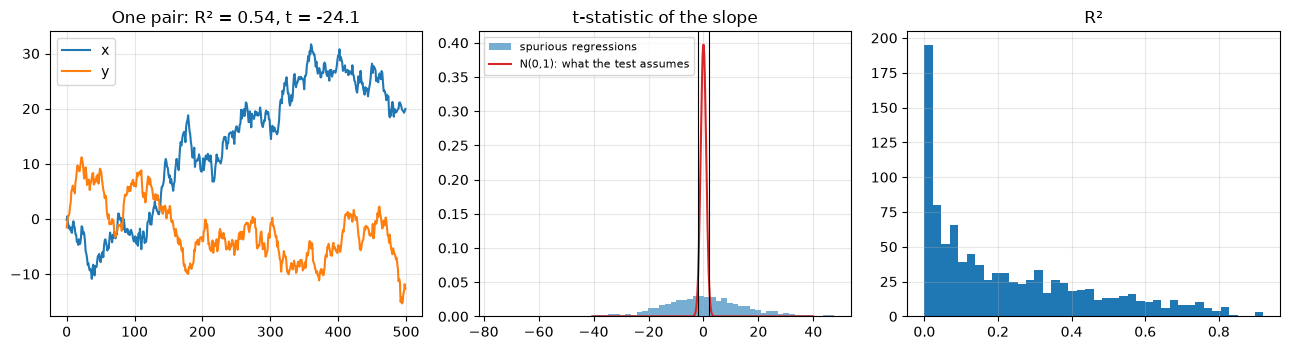

In [13]:
n, trials = 500, 1000
t_vals, r2_vals, t_hac = [], [], []
for _ in range(trials):
    x = simulate.random_walk(n, seed=rng)
    y = simulate.random_walk(n, seed=rng)
    fit = stats.ols(y, x)
    t_vals.append(fit.tvalues["x"])
    r2_vals.append(fit.rsquared)
    t_hac.append(stats.ols(y, x, cov_type="HAC").tvalues["x"])
t_vals, r2_vals, t_hac = map(np.asarray, (t_vals, r2_vals, t_hac))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(x, label="x")
axes[0].plot(y, label="y")
axes[0].set_title(f"One pair: R² = {r2_vals[-1]:.2f}, t = {t_vals[-1]:.1f}")
axes[0].legend()
grid = np.linspace(-40, 40, 400)
axes[1].hist(t_vals, bins=60, density=True, alpha=0.6, label="spurious regressions")
axes[1].plot(grid, sps.norm.pdf(grid), "C3", label="N(0,1): what the test assumes")
for side in (-1.96, 1.96):
    axes[1].axvline(side, color="k", lw=0.8)
axes[1].set_title("t-statistic of the slope")
axes[1].legend(fontsize=8)
axes[2].hist(r2_vals, bins=40)
axes[2].set_title("R²")
fig.tight_layout()

print(f"share with |t| > 1.96: {(np.abs(t_vals) > 1.96).mean():.0%} (should be 5%)")
print(f"with HAC errors:       {(np.abs(t_hac) > 1.96).mean():.0%}")
print(
    f"median |t| = {np.median(np.abs(t_vals)):.1f};  share with R² > 0.5: {(r2_vals > 0.5).mean():.0%}"
)

About 90% of regressions between unrelated random walks are "significant", with typical
t-statistics around 10 and often a large $R^2$. Granger and Newbold (1974) showed this by
simulation. Phillips (1986) proved why: when $y$ and $x$ are independent $I(1)$ series, the
residual is itself a random walk, every OLS assumption about the errors fails, $\hat\beta$
converges to a *random variable* instead of 0, and the t-statistic grows like $\sqrt T$.
More data makes it worse:

In [14]:
by_length = {}
for T in (100, 500, 2000):
    tt = [
        stats.ols(simulate.random_walk(T, seed=rng), simulate.random_walk(T, seed=rng)).tvalues["x"]
        for _ in range(300)
    ]
    by_length[T] = {
        "share |t| > 1.96": np.mean(np.abs(tt) > 1.96),
        "median |t|": np.median(np.abs(tt)),
    }
pd.DataFrame(by_length).T.rename_axis("T")

,share |t| > 1.96,median |t|
T,,
100,0.7600,4.5718
500,0.9000,10.0811
2000,0.9567,20.4495


HAC error bars help only a little: the problem is not the size of the error bars but that
the model itself is wrong. *Physics analogy:* two independent diffusing particles. In any
single run both wander far from the origin, and over a finite window their trajectories
look correlated (both drifted up, say). The sample correlation of two independent random
walks does not shrink to 0 as the window grows; its distribution stays broad.

**Why this matters for stat arb:** regressing one price on another and trusting the
t-statistic or $R^2$ is exactly this mistake. Two cures, coming next: difference the data
(regress returns on returns, Exercise 2), or test whether the *residual* is stationary,
which is cointegration (Module 5).

## 5. Real data: SPY returns and volatility clustering

Twenty years of SPY daily data. First the real-data version of Section 2d: the log price
is $I(1)$-like, and differencing it (log returns) gives a stationary-looking series.

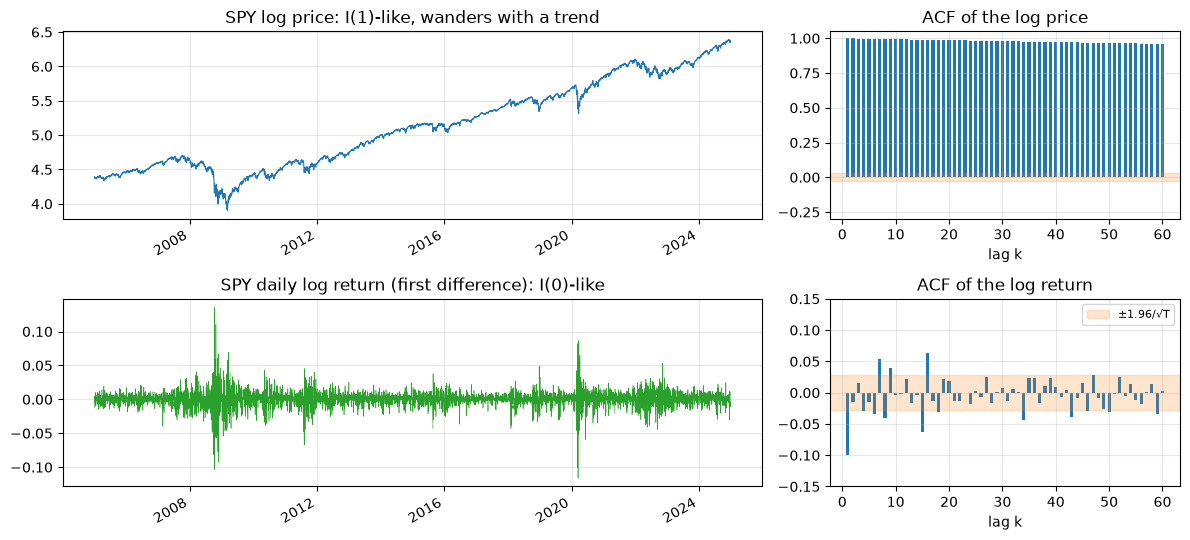

In [15]:
prices = data.load_prices("SPY", "2005-01-01", "2024-12-31")["SPY"]
log_price = np.log(prices)
r = returns.log_returns(prices)
T = len(r)

fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [2, 1]})
log_price.plot(ax=axes[0, 0], lw=0.8)
axes[0, 0].set_title("SPY log price: I(1)-like, wanders with a trend")
axes[0, 0].set_xlabel("")
plot_acf(axes[0, 1], stats.acf(log_price, 60), T, "ACF of the log price")
r.plot(ax=axes[1, 0], lw=0.4, color="C2")
axes[1, 0].set_title("SPY daily log return (first difference): I(0)-like")
axes[1, 0].set_xlabel("")
plot_acf(axes[1, 1], stats.acf(r, 60), T, "ACF of the log return")
axes[1, 1].set_ylim(-0.15, 0.15)
axes[1, 1].legend(fontsize=8)
fig.tight_layout()
save(fig, "differencing-spy.png")

The return series is stationary in mean but visibly not in variance: calm stretches and
bursts (2008, 2020). The ACF of *squared* returns measures that:

T = 5032, white-noise band ±0.028


lag,1,2,3,4,5
log price,0.9993,0.9986,0.9979,0.9972,0.9965
return,-0.1003,-0.0157,0.0157,-0.0292,-0.0145
squared return,0.2767,0.4833,0.2473,0.2959,0.3190


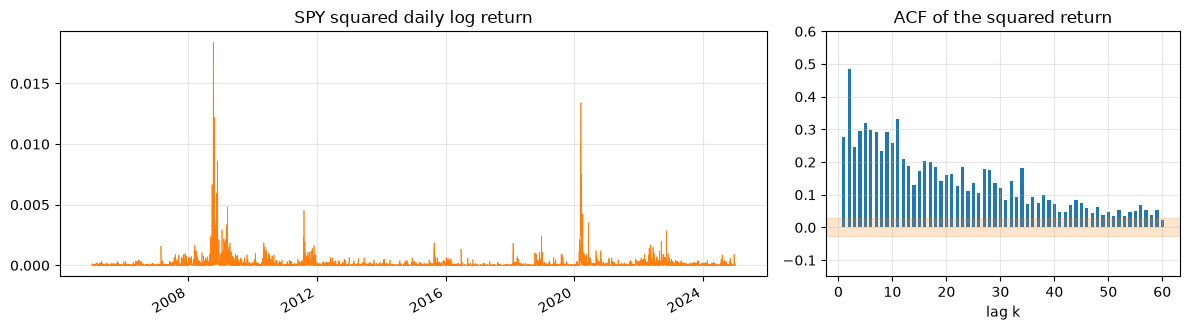

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [2, 1]})
(r**2).plot(ax=axes[0], lw=0.5, color="C1")
axes[0].set_title("SPY squared daily log return")
axes[0].set_xlabel("")
plot_acf(axes[1], stats.acf(r**2, 60), T, "ACF of the squared return")
axes[1].set_ylim(-0.15, 0.6)
fig.tight_layout()

summary = pd.DataFrame(
    {
        "log price": stats.acf(log_price, 5),
        "return": stats.acf(r, 5),
        "squared return": stats.acf(r**2, 5),
    }
).iloc[1:]
print(f"T = {T}, white-noise band ±{stats.acf_band(T):.3f}")
summary.T

- **Log price:** ACF near 1 at every lag shown, the unit-root signature. Prices are
  approximately $I(1)$.
- **Returns:** autocorrelations are small. Lag 1 is about −0.1, outside the band (a little
  short-term reversal, which we met in Module 1 as monthly volatility below daily), but
  there is almost no linear predictability. Returns are approximately $I(0)$.
- **Squared returns:** large and persistent positive autocorrelation, lasting weeks to
  months. Big moves follow big moves: **volatility clustering**. Returns are uncorrelated
  but *not independent*; their variance is predictable. Models of this (ARCH and GARCH)
  are beyond this project, but its consequences are everywhere: rolling volatility,
  heteroskedastic regression errors, and the HAC correction above.

One caution: the white-noise band assumes i.i.d. data. With volatility clustering, the
sampling error of the return ACF is larger than $1/\sqrt T$, so a few bars just outside
the band are weaker evidence than they look.

## 6. Exercises

1. **AR(1) stationary variance.** Derive $\operatorname{Var}(x_t) = \sigma^2/(1-\phi^2)$ for
   a stationary AR(1), and check it on a simulated ensemble.
2. **Differencing cures spurious regression.** Regress the *differences* of two independent
   random walks on each other (1,000 pairs) and show the t-statistics now follow the
   nominal distribution, with about 5% beyond ±1.96.
3. **Estimating $\phi$ near a unit root.** For $\phi \in \lbrace 0.5, 0.9, 0.99, 1.0 \rbrace$ and 250
   observations, estimate $\phi$ by regressing $x_t$ on $x_{t-1}$, over many simulations.
   How biased and how noisy is $\hat\phi$ as $\phi \to 1$? Why does this matter for
   deciding whether a spread is mean-reverting?

In [17]:
# Exercise 1

In [18]:
# Exercise 2

In [19]:
# Exercise 3